## ¿Cuántos viajes se iniciarán en una estación o zona en un periodo futuro?

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

from sklearn.model_selection import ParameterGrid


/Users/saramarquez/Documents/masters/trimestre-sep-dic-2026/mlops/week5/TC5061-Proyecto-Equipo41/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [50]:
df = pd.read_csv('../data/interim/joined_trips_stations-2026_09.csv')
for col in ['Inicio_del_viaje','Fin_del_viaje']:
    df[col] = pd.to_datetime(df[col])

df.head()

,Viaje_Id,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,Duracion_minutos,Origen_Nombre,Origen_Latitud,Origen_Longitud,Origen_dpcapacity,Destino_Nombre,Destino_Latitud,Destino_Longitud,Destino_dpcapacity
0,45705294,2026-09-01 00:00:59,2026-09-01 00:18:55,283,49,17.933333,(GDL-210) Av. Washington / Calz. Independenci,20.657750,-103.351320,31,(GDL-047) C. Robles Gil / Av. Vallarta,20.674931,-103.362351,15
1,45705295,2026-09-01 00:01:36,2026-09-01 00:17:52,67,383,16.266667,(GDL-065) C. Simón Bolivar / Av. La Paz,20.672206,-103.372588,19,(GDL-240)Hilarion Romero Gil/Gabriela Mistral,20.689988,-103.344978,19
2,45705301,2026-09-01 00:03:36,2026-09-01 00:19:31,395,357,15.916667,(GDL-276) Francisco de Quevedo / Miguel Lerdo,20.671045,-103.381349,19,(GDL-268)Heroico Colegio Militar/Revolución,20.666469,-103.334026,15
3,45705303,2026-09-01 00:03:59,2026-09-01 00:07:07,371,57,3.133333,(GDL-237)Av. Ramón Corona / C. Leandro Valle,20.669189,-103.346173,15,(GDL-055) C. Degollado /C.Prisciliano Sánchez,20.672696,-103.345366,15
4,45705304,2026-09-01 00:04:09,2026-09-01 00:30:19,357,80,26.166667,(GDL-268)Heroico Colegio Militar/Revolución,20.666469,-103.334026,15,(GDL-078) C. Comercio / C. La Paz,20.668880,-103.348460,15


### Creando variable a predecir Y 
Si nuestra variable a predecir es la cantidad de viajes que se iniciarán en un periodo de tiempo en una misma estación, entonces debemos de contar la cantidad de viajes que ocurrieron en un periodo de tiempo específico. Como no se define una métrica concreta desde el negocio, se escoge hora como la unidad de análisis.


In [51]:

df["Dia"] = df["Inicio_del_viaje"].dt.day_name()
df["Mes"] = df["Inicio_del_viaje"].dt.month
df["Hora"] = df["Inicio_del_viaje"].dt.floor("h").dt.strftime("%H:%M:%S")

In [52]:
p1_df = df.copy()

p1_df = (
    df.groupby(["Origen_Id", "Hora", "Dia", "Mes"])
    .size()
    .rename("Viajes")
    .reset_index()
)

p1_df.head()

,Origen_Id,Hora,Dia,Mes,Viajes
0,2,00:00:00,Friday,9,3
1,2,00:00:00,Saturday,9,3
2,2,00:00:00,Sunday,9,2
3,2,00:00:00,Thursday,9,1
4,2,05:00:00,Thursday,9,1


### Considerando 0 viajes

In [53]:
origins = df[["Origen_Id"]].drop_duplicates()

hours = pd.DataFrame({
    "Hora": [f"{hour:02d}:00:00" for hour in range(24)]
})

dates = df[["Dia", "Mes"]].drop_duplicates()

combinations = (
    origins
    .merge(hours, how="cross")
    .merge(dates, how="cross")
)

p1_df = (
    combinations
    .merge(p1_df, on=["Origen_Id", "Hora", "Dia", "Mes"], how="left")
    .fillna({"Viajes": 0})
    .astype({"Viajes": int})
    .sort_values(["Origen_Id", "Mes", "Dia", "Hora"])
    .reset_index(drop=True)
)
p1_df

,Origen_Id,Hora,Dia,Mes,Viajes
0,2,00:00:00,Friday,9,3
1,2,01:00:00,Friday,9,0
2,2,02:00:00,Friday,9,0
3,2,03:00:00,Friday,9,0
4,2,04:00:00,Friday,9,0
...,...,...,...,...,...
78619,519,19:00:00,Wednesday,9,7
78620,519,20:00:00,Wednesday,9,0
78621,519,21:00:00,Wednesday,9,0
78622,519,22:00:00,Wednesday,9,1


# EDA

### Análisis univariado
Para este análisis nos concentraremos en la variable de salida, ya que los predictores son valores repetitivos y conocidos. 
Observamos que tenemos una distribución asimétrica, con una cola hacia la derecha. Obtenemos el valor máximo que es de 141 viajes en una sola hora. 

In [54]:
p1_df.Viajes.describe()

count    78624.000000
mean         6.223265
std         10.515769
min          0.000000
25%          0.000000
50%          2.000000
75%          8.000000
max        219.000000
Name: Viajes, dtype: float64

In [55]:
max_viajes = p1_df.Viajes.max()
max_viajes

np.int64(219)

<Axes: >

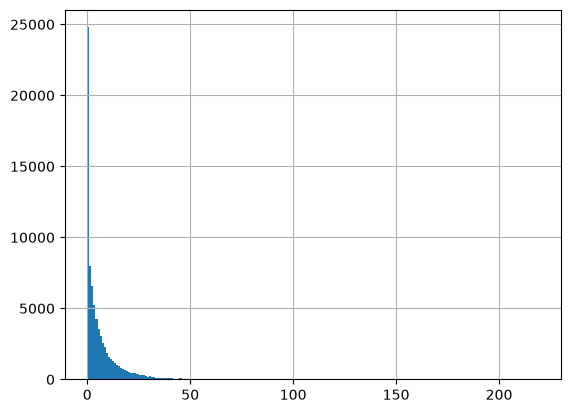

In [56]:
p1_df.Viajes.hist(range=[0, max_viajes], bins= max_viajes+1)

### Análisis bivariado
Para este análisis compararemos la variable de salida con los predictores día de la semana y hora. Como estamos haciendo el análisis inicial con solo el mes de Septiembre, omitimos esta relación. Al hacer el análisis anual es posible que se observen diferentes picos dependiendo del mes.

#### Día y viajes
Se observan picos no tan pronunciados en Martes y Miércoles, y comienzan a decrementar los viajes de Jueves a Domingo.

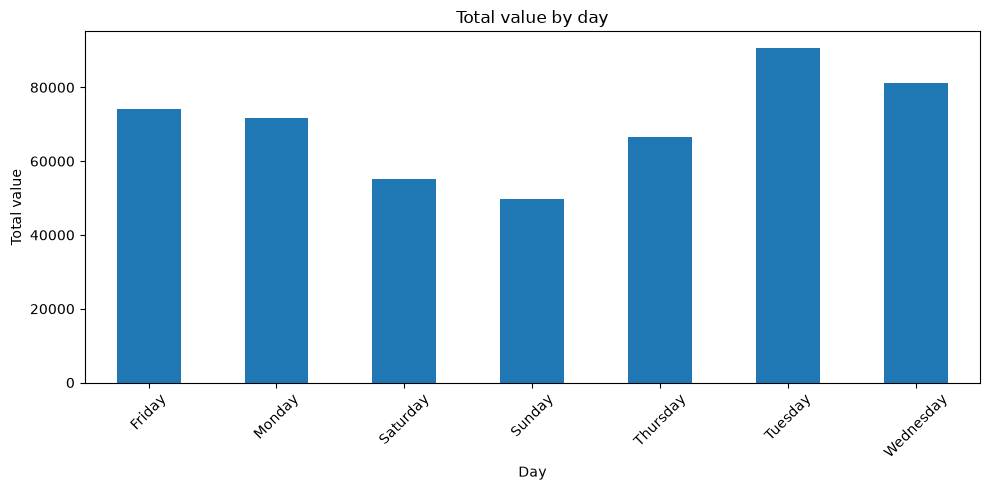

In [57]:

daily_totals = p1_df.groupby("Dia")["Viajes"].sum()

fig, ax = plt.subplots(figsize=(10, 5))
daily_totals.plot.bar(ax=ax)

ax.set_xlabel("Day")
ax.set_ylabel("Total value")
ax.set_title("Total value by day")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Hora y viajes
Se observan picos claros en la hora de entrada y salida laboral. Además observamos otra regla de negocio, miBici bloquea el inicio de uso de bicicletas de la 1am a las 5am.

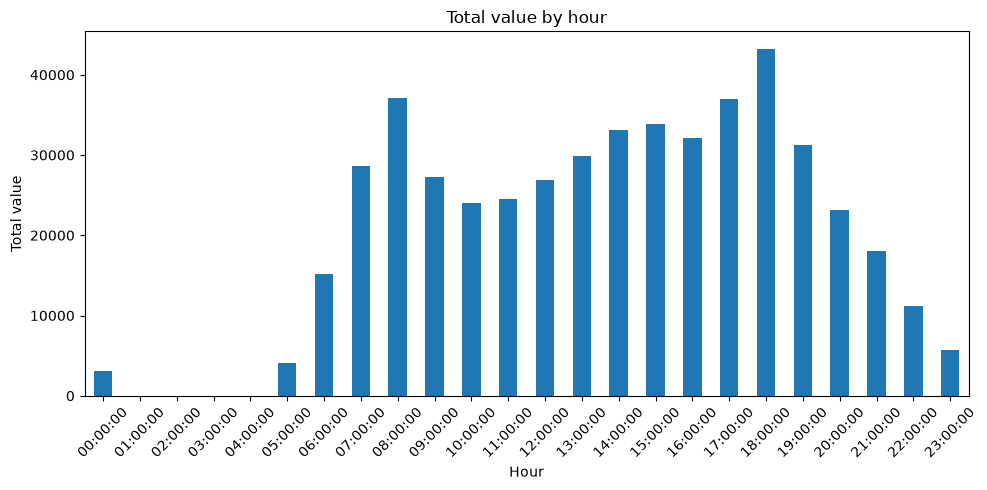

In [58]:

hourly_totals = p1_df.groupby("Hora")["Viajes"].sum()

fig, ax = plt.subplots(figsize=(10, 5))
hourly_totals.plot.bar(ax=ax)

ax.set_xlabel("Hour")
ax.set_ylabel("Total value")
ax.set_title("Total value by hour")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Consumir datos y separar datos entrenamiento y prueba

In [73]:
df = pd.read_csv('../data/interim/joined_trips_stations-2026_09-2026-06.csv')

for col in ['Inicio_del_viaje','Fin_del_viaje']:
    df[col] = pd.to_datetime(df[col])

p1_df = df[["Origen_Id", "Inicio_del_viaje"]].copy()
p1_df["Inicio_del_viaje"] = pd.to_datetime(p1_df["Inicio_del_viaje"])
p1_df["Fecha"] = p1_df["Inicio_del_viaje"].dt.floor("h")

counts = p1_df.groupby(["Origen_Id", "Fecha"]).size()

index = pd.MultiIndex.from_product(
    [
        p1_df["Origen_Id"].unique(),
        pd.date_range(p1_df["Fecha"].min(), p1_df["Fecha"].max(), freq="h"),
    ],
    names=["Origen_Id", "Fecha"],
)

p1_df = (
    counts.reindex(index, fill_value=0)
    .rename("Viajes")
    .reset_index()
)

p1_df["Hora"] = p1_df["Fecha"].dt.hour
p1_df["Dia"] = p1_df["Fecha"].dt.day
p1_df["Mes"] = p1_df["Fecha"].dt.month

p1_df


,Origen_Id,Fecha,Viajes,Hora,Dia,Mes
0,283,2026-06-01 00:00:00,0,0,1,6
1,283,2026-06-01 01:00:00,0,1,1,6
2,283,2026-06-01 02:00:00,0,2,1,6
3,283,2026-06-01 03:00:00,0,3,1,6
4,283,2026-06-01 04:00:00,0,4,1,6
...,...,...,...,...,...,...
1379083,405,2026-09-30 19:00:00,0,19,30,9
1379084,405,2026-09-30 20:00:00,0,20,30,9
1379085,405,2026-09-30 21:00:00,0,21,30,9
1379086,405,2026-09-30 22:00:00,0,22,30,9


In [80]:
p1_df.drop(columns=["Mes", "Fecha"])

,Origen_Id,Viajes,Hora,Dia
0,283,0,0,1
1,283,0,1,1
2,283,0,2,1
3,283,0,3,1
4,283,0,4,1
...,...,...,...,...
1379083,405,0,19,30
1379084,405,0,20,30
1379085,405,0,21,30
1379086,405,0,22,30


Dividimos los datos de entrenamiento y prueba en orden cronológico, para cumplir con el requerimiento de predecir el "futuro".

In [81]:
TRAIN_END = pd.Timestamp("2026-08-31")
VALIDATION_END = pd.Timestamp("2026-09-30")

FEATURES = ["Origen_Id", "Hora", "Dia"] # Ignoramos Mes porque no estamos considerando un año entero
TARGET = "Viajes"

train = p1_df[p1_df["Fecha"] <= TRAIN_END]
test = p1_df[p1_df["Fecha"] >= VALIDATION_END]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

### Modelado 


In [87]:


mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment(f"mibici-P1-experimentación")

grid = ParameterGrid({
    "alpha": [0.1, 1.0, 10.0, 100.0],
    "fit_intercept": [True, False],
})

In [ ]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


results = []
best_model = None
best_run_id = None
best_mae = float("inf")

for params in grid:
    model = make_pipeline(
        StandardScaler(),
        Ridge(**params, solver="lsqr", tol=1e-4, max_iter=10_000),
    )

    run_name = (
        f"P1_ridge_alpha_{params['alpha']}"
        f"_intercept_{params['fit_intercept']}"
    )

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({
            **params,
            "model": "Ridge",
            "solver": "lsqr",
            "tol": 1e-4,
            "max_iter": 10_000,
        })

        model.fit(X_train, y_train)

        train_predictions = np.maximum(0, model.predict(X_train))
        test_predictions = np.maximum(0, model.predict(X_test))
        metrics = {
            "train_mae": mean_absolute_error(y_train, train_predictions),
            "train_rmse": np.sqrt(
                mean_squared_error(y_train, train_predictions)
            ),
            "train_r2": r2_score(y_train, train_predictions),
            "test_mae": mean_absolute_error(y_test, test_predictions),
            "test_rmse": np.sqrt(
                mean_squared_error(y_test, test_predictions)
            ),
            "test_r2": r2_score(y_test, test_predictions),
        }
        mlflow.log_metrics(metrics)

        results.append({
            **params,
            **metrics,
            "run_id": run.info.run_id,
        })

        if metrics["test_mae"] < best_mae:
            best_mae = metrics["test_mae"]


            best_model = model
            best_run_id = run.info.run_id

results_df = pd.DataFrame(results).sort_values("test_mae")
results_df

🏃 View run P1_ridge_alpha_0.1_intercept_True at: http://127.0.0.1:5000/#/experiments/1/runs/591c488f3019415d8b0054dfeb2b642a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run P1_ridge_alpha_0.1_intercept_False at: http://127.0.0.1:5000/#/experiments/1/runs/c8c32a48c3d64aa998cb844a90b4dd60
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run P1_ridge_alpha_1.0_intercept_True at: http://127.0.0.1:5000/#/experiments/1/runs/6febe77f372a44e8874125a40f34cfd6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run P1_ridge_alpha_1.0_intercept_False at: http://127.0.0.1:5000/#/experiments/1/runs/12c8891f099246bab901986f8a8ab19c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run P1_ridge_alpha_10.0_intercept_True at: http://127.0.0.1:5000/#/experiments/1/runs/7860f82af5b34cc39e73e8e3d032ced5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run P1_ridge_alpha_10.0_intercept_False at: http://127.0.0.1:5000

,alpha,fit_intercept,train_mae,train_rmse,train_r2,test_mae,test_rmse,test_r2,run_id
0,0.1,True,1.215783,2.172103,0.109915,1.735636,3.251611,0.042957,591c488f3019415d8b0054dfeb2b642a
2,1.0,True,1.215783,2.172103,0.109915,1.735636,3.251612,0.042957,6febe77f372a44e8874125a40f34cfd6
4,10.0,True,1.215783,2.172104,0.109915,1.735636,3.251612,0.042957,7860f82af5b34cc39e73e8e3d032ced5
6,100.0,True,1.215784,2.172105,0.109914,1.735640,3.251622,0.042951,8cceb08d0e95483e8712f314e90ff858
1,0.1,False,1.034157,2.333061,-0.026887,1.776872,3.581396,-0.161017,c8c32a48c3d64aa998cb844a90b4dd60
3,1.0,False,1.034157,2.333061,-0.026887,1.776872,3.581396,-0.161017,12c8891f099246bab901986f8a8ab19c
5,10.0,False,1.034157,2.333062,-0.026888,1.776873,3.581398,-0.161018,adf5f7642f9441b4b885629d968ebf65
7,100.0,False,1.034159,2.333076,-0.026901,1.776882,3.581417,-0.161031,ba20fe7be4ff481298432d8ee11abda9
